# COMP3032 Part B: Smart Greenhouse crop health prediction
**Mohammad Adib (Eddie) Amiri**

**Question:** do current crop images improve prediction of `next_health_score` for an unseen greenhouse episode, compared with the tabular solution submitted in Part A?

This notebook keeps Part A's regression target and 12 available tabular inputs. It compares a small image CNN, a tabular multilayer perceptron (MLP), and a CNN + tabular fusion network. A colour-summary Ridge model checks whether a simpler use of the images is competitive. All model choices use only `train.csv`. The supplied `validation.csv` is a final common benchmark, already examined in Part A, rather than a new untouched dataset.

## Run instructions
Place this notebook beside the supplied dataset ZIP (a filename ending in `(1).zip` also works), or the extracted `COMP3032_greenhouse_dataset` folder. Otherwise set `DATA_LOCATION` below. Restart the kernel and run all cells in order. No separate Python file, pretrained weights, GPU or paid service is required.

Dependencies: `pip install torch numpy pandas scikit-learn matplotlib pillow jupyter`. The saved run uses Python 3.12, PyTorch 2.14.1+cpu, NumPy 2.3.5, pandas 2.2.3, scikit-learn 1.8.0 and Matplotlib 3.10.8. For the same versions, use `torch==2.14.1 numpy==2.3.5 pandas==2.2.3 scikit-learn==1.8.0 matplotlib==3.10.8`; the CPU PyTorch index is `https://download.pytorch.org/whl/cpu`. GroupKFold with shuffling requires scikit-learn >= 1.6.

The code deliberately runs on CPU with four threads. Training takes several minutes; wall time depends on the computer. Every table and figure used in the accompanying Part B PDF report has a saved output below. Running all cells also recreates supporting tables and figures in `student_part_b_results`.

In [1]:
from pathlib import Path
import io, zipfile, random, time, copy, json, hashlib, platform
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from IPython.display import display

SEED = 42
DATA_LOCATION = None  # Optional: Path('path/to/dataset.zip_or_folder')
RESULTS = Path('student_part_b_results')
RESULTS.mkdir(exist_ok=True)
CPU_THREADS = 4
BATCH_SIZE = 256
MAX_EPOCHS = 50
PATIENCE = 8
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001
torch.set_num_threads(CPU_THREADS)
torch.use_deterministic_algorithms(True)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(SEED)
versions = {'Python': platform.python_version(), 'PyTorch': torch.__version__,
            'NumPy': np.__version__, 'pandas': pd.__version__,
            'scikit-learn': sklearn.__version__, 'Matplotlib': matplotlib.__version__}
print('Environment:', versions)
print('Device: CPU; threads:', torch.get_num_threads())
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
pd.set_option('display.max_columns', 12)

def save_plot(name):
    plt.tight_layout()
    plt.savefig(RESULTS / f'{name}.png', dpi=180, bbox_inches='tight')
    plt.show()

def metrics(actual, predicted):
    return {'RMSE': float(np.sqrt(mean_squared_error(actual, predicted))),
            'MAE': float(mean_absolute_error(actual, predicted)),
            'R2': float(r2_score(actual, predicted))}

Environment: {'Python': '3.12.14', 'PyTorch': '2.14.1+cpu', 'NumPy': '2.3.5', 'pandas': '2.2.3', 'scikit-learn': '1.8.0', 'Matplotlib': '3.10.8'}
Device: CPU; threads: 4


## 1. Load only the training split and audit the image links
`image_index` refers to a row of the **split-specific** NPZ array. Filtering CSV rows must not change those indices. I load images using the retained `image_index`, never by assuming the filtered row number still matches the original array. The terminal row has no next-step label and is removed; targets are never imputed.

The supplied pairing is treated as a current-step image. Index checks can detect a broken join but cannot independently establish camera timing: the image generator and timestamp records were not supplied. This availability assumption is a limitation.

In [2]:
if DATA_LOCATION is None:
    candidates = []
    for base in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
        for sub in [base, base / 'upload', base / 'data']:
            candidates += sorted(sub.glob('COMP3032_greenhouse_dataset*.zip'))
            candidates.append(sub / 'COMP3032_greenhouse_dataset')
    DATA_LOCATION = next((p for p in candidates if p.exists()), None)
if DATA_LOCATION is None:
    raise FileNotFoundError('Set DATA_LOCATION to the supplied ZIP or extracted dataset folder.')
DATA_LOCATION = Path(DATA_LOCATION)

def read_member(name):
    if DATA_LOCATION.is_dir():
        return (DATA_LOCATION / name).read_bytes()
    with zipfile.ZipFile(DATA_LOCATION) as archive:
        matches = [n for n in archive.namelist() if Path(n).name == name]
        if len(matches) != 1:
            raise ValueError(f'Expected one archive member named {name}, found {len(matches)}')
        return archive.read(matches[0])

def read_csv(name):
    return pd.read_csv(io.BytesIO(read_member(name)))

def read_images(name):
    with np.load(io.BytesIO(read_member(name)), allow_pickle=False) as archive:
        return archive['images'].copy()

TARGET = 'next_health_score'
NUMERIC = ['day', 'outside_temp_c', 'outside_humidity_pct', 'solar_w_m2',
           'inside_temp_c', 'inside_humidity_pct', 'co2_ppm', 'soil_moisture', 'vpd_kpa']
CATEGORICAL = ['cultivar', 'season', 'action_name']
FEATURES = NUMERIC + CATEGORICAL
FORBIDDEN = {'health_score', 'disease_severity', 'reward', 'biomass_index',
             'fruit_index', 'episode_id', 'image_index', 'terminal', 'action',
             'energy_kwh', 'water_l'}
assert not set(FEATURES) & FORBIDDEN
assert not any(c.startswith('next_') for c in FEATURES)

train_raw = read_csv('train.csv')
train_images_raw = read_images('train_images.npz')
dictionary = read_csv('data_dictionary.csv')

def audit_split(df, images, name):
    assert images.dtype == np.uint8 and images.shape == (len(df), 32, 32, 3)
    assert not df.duplicated().any() and not df.duplicated(['episode_id', 'day']).any()
    assert df.groupby('episode_id').size().eq(60).all()
    assert df.groupby('episode_id')['day'].apply(lambda x: x.tolist() == list(range(60))).all()
    assert df.image_index.dtype.kind in 'iu'
    assert np.array_equal(np.sort(df.image_index), np.arange(len(images)))
    assert df[TARGET].isna().equals(df.terminal.eq(1))
    assert df.loc[df[TARGET].notna(), TARGET].between(0, 1).all()
    assert df[FEATURES].notna().all().all()
    expected = df.groupby('episode_id').health_score.shift(-1)
    assert np.allclose(df[TARGET], expected, equal_nan=True)
    return {'split': name, 'raw_rows': len(df), 'episodes': df.episode_id.nunique(),
            'labelled_rows': df[TARGET].notna().sum(), 'images': len(images),
            'missing_inputs': int(df[FEATURES].isna().sum().sum())}

train_audit = audit_split(train_raw, train_images_raw, 'Training')
data = train_raw.dropna(subset=[TARGET]).reset_index(drop=True)
images = train_images_raw[data.image_index.to_numpy()]
y = data[TARGET].to_numpy(dtype=np.float32)
groups = data.episode_id.to_numpy()
image_hashes = [hashlib.sha256(a.tobytes()).hexdigest() for a in images]
print('Data source:', DATA_LOCATION.name)
display(pd.DataFrame([train_audit]))
print('Training image shape/dtype/range:', images.shape, images.dtype, (images.min(), images.max()))
print('Exact duplicate labelled training images:', len(image_hashes) - len(set(image_hashes)))
display(dictionary)
display(data[['episode_id', 'day', 'image_index', TARGET]].head(4))

Data source: COMP3032_greenhouse_dataset(1).zip


,split,raw_rows,episodes,labelled_rows,images,missing_inputs
0,Training,10800,180,10620,10800,0


Training image shape/dtype/range: (10620, 32, 32, 3) uint8 (np.uint8(6), np.uint8(240))
Exact duplicate labelled training images: 0


,variable,description
0,episode_id,Trajectory identifier; split only by episode
1,day,Simulation step
2,cultivar,Synthetic cultivar A/B/C
3,season,cool/mild/warm regime
4,action,"0 hold, 1 irrigate, 2 ventilate, 3 heat, 4 sha..."
5,outside_temp_c,Outdoor temperature
6,outside_humidity_pct,Outdoor relative humidity
7,solar_w_m2,Solar radiation
8,inside_temp_c,Greenhouse air temperature
9,inside_humidity_pct,Greenhouse relative humidity


,episode_id,day,image_index,next_health_score
0,0,0,0,0.901321
1,0,1,1,0.888971
2,0,2,2,0.852164
3,0,3,3,0.804902


## 2. Preserve Part A's information boundary and split whole episodes
The 12 tabular inputs are unchanged from Part A: nine current measurements/context variables and three nominal categories. Current latent health and disease are **not** input features. All future fields, reward, crop indices, identifiers and duplicated action/cost fields remain excluded. The intended action is assumed known before the prediction.

For development I reuse the **first fold** of Part A's shuffled five-fold GroupKFold (seed 42): 144 episodes for fitting and 36 for early stopping and configuration comparison. This is one development split, not a new five-fold CV estimate. It limits CPU cost but introduces split sensitivity. The supplied 30-episode validation split is not used for early stopping, architecture selection or seed selection.

Numeric medians/scalers and one-hot categories are fitted only on development-fit episodes. Images are scaled by 255, then standardised using per-channel means and SDs calculated only from those same episodes. I do not normalise each image separately, because that would remove absolute colour information. There are no missing inputs here; imputers only make the tabular pipeline explicit.

Encoded tabular dimension: 21
Fit-only RGB mean: [0.25795 0.26834 0.14852] SD: [0.03668 0.13018 0.02678]


,partition,episodes,rows
0,Development fit,144,8496
1,Development assessment,36,2124


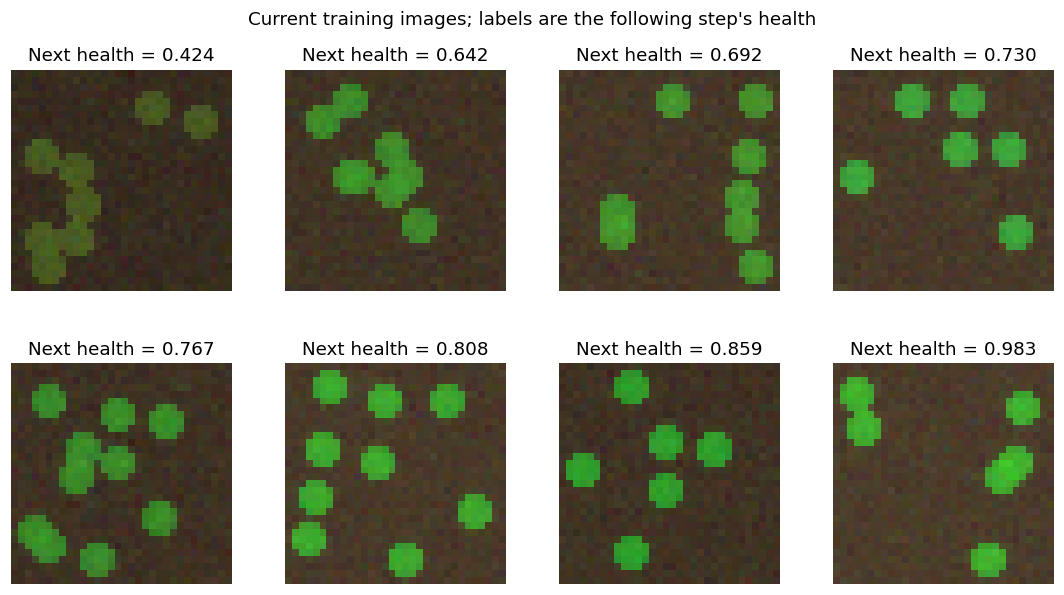

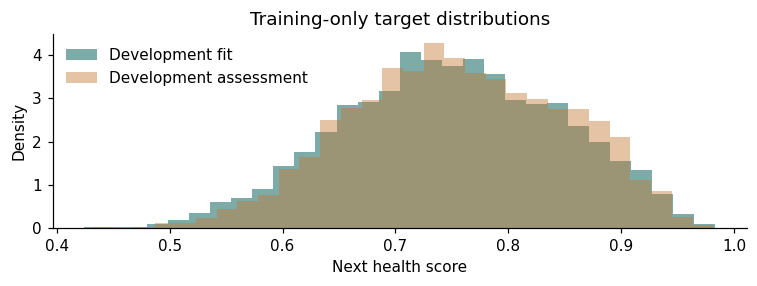

In [3]:
folds = list(GroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(data, y, groups))
fit_idx, dev_idx = folds[0]
assert set(groups[fit_idx]).isdisjoint(groups[dev_idx])

def make_preprocessor(scale=True):
    steps = [('impute', SimpleImputer(strategy='median'))]
    if scale:
        steps.append(('scale', StandardScaler()))
    return ColumnTransformer([
        ('numeric', Pipeline(steps), NUMERIC),
        ('category', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), CATEGORICAL)
    ])

pre_dev = make_preprocessor()
tab_fit = pre_dev.fit_transform(data.iloc[fit_idx][FEATURES]).astype('float32')
tab_dev = pre_dev.transform(data.iloc[dev_idx][FEATURES]).astype('float32')

def image_stats(array):
    scaled = array.astype(np.float32) / 255.0
    return scaled.mean(axis=(0, 1, 2), keepdims=True), scaled.std(axis=(0, 1, 2), keepdims=True)

def image_tensor(array, mean, std):
    scaled = (array.astype(np.float32) / 255.0 - mean) / np.maximum(std, 1e-6)
    return torch.from_numpy(np.ascontiguousarray(scaled.transpose(0, 3, 1, 2)))

mean_dev, std_dev = image_stats(images[fit_idx])
img_fit = image_tensor(images[fit_idx], mean_dev, std_dev)
img_dev = image_tensor(images[dev_idx], mean_dev, std_dev)
tab_fit, tab_dev = torch.from_numpy(tab_fit), torch.from_numpy(tab_dev)
y_fit, y_dev = torch.from_numpy(y[fit_idx]), torch.from_numpy(y[dev_idx])
split_table = pd.DataFrame([
    {'partition': 'Development fit', 'episodes': len(np.unique(groups[fit_idx])), 'rows': len(fit_idx)},
    {'partition': 'Development assessment', 'episodes': len(np.unique(groups[dev_idx])), 'rows': len(dev_idx)}
])
display(split_table)
print('Encoded tabular dimension:', tab_fit.shape[1])
print('Fit-only RGB mean:', mean_dev.ravel().round(5), 'SD:', std_dev.ravel().round(5))

fig, axes = plt.subplots(2, 4, figsize=(10, 5.4), gridspec_kw={'hspace': 0.33, 'wspace': 0.12})
ordered = fit_idx[np.argsort(y[fit_idx])]
sample_idx = ordered[np.linspace(0, len(ordered) - 1, 8).astype(int)]
for ax, idx in zip(axes.flat, sample_idx):
    ax.imshow(images[idx])
    ax.set_title(f'Next health = {y[idx]:.3f}')
    ax.axis('off')
fig.suptitle("Current training images; labels are the following step's health", fontsize=12)
# Reserve a real gap between rows: tight_layout can overlap titles on square images.
fig.subplots_adjust(left=0.015, right=0.985, bottom=0.015, top=0.88)
fig.savefig(RESULTS / 'image_examples.png', dpi=180, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(7, 2.7))
ax.hist(y[fit_idx], bins=30, alpha=0.6, density=True, label='Development fit', color='#26746c')
ax.hist(y[dev_idx], bins=30, alpha=0.45, density=True, label='Development assessment', color='#c47c38')
ax.set(xlabel='Next health score', ylabel='Density', title='Training-only target distributions')
ax.legend(frameon=False)
save_plot('target_distribution')

## 3. Small neural networks with interpretable comparisons
All networks use ReLU hidden units, dropout 0.1 and a sigmoid regression output in [0, 1]. The CNN uses 3x3 convolutions, 2x2 max pooling and global average pooling. Shared convolutional filters learn local colour/shape patterns without a large flattened image layer. It is trained from scratch at the original resolution.

| Model | Role |
|---|---|
| Tabular MLP | Tests whether changing the tabular model alone explains an improvement. 21 encoded inputs -> 32 -> 16 -> 32 -> 1. |
| Image CNN | Tests images alone: channels 3 -> 8 -> 16 -> 32; pooling -> 32 -> 1. It cannot observe the intended action or environment. |
| Fusion | Concatenates the CNN's 32 image features with a 16-dimensional tabular embedding, then 48 -> 32 -> 1. |
| Fusion + flips | Same capacity; independently random horizontal/vertical flips during training only. Tests orientation invariance. |

No colour jitter, resizing, pretrained network, recurrent model or large architecture search is used. Colour may carry the health cue; synthetic leaf orientation has no documented semantics. Whether flips actually help is checked rather than assumed. A temporal model is left for future work because it changes the information budget and comparison with Part A.

**Training:** mean squared error (MSE), Adam, learning rate 0.001, weight decay 0.0001, batches of 256, at most 50 epochs. MSE is consistent with the RMSE selection criterion. Early stopping restores the lowest development MSE checkpoint; patience is eight epochs without improvement of at least 0.00001 RMSE. Train RMSE is measured in evaluation mode without augmentation or dropout for a comparable learning curve. The same split and seed 42 are used for all four configurations. RMSE is primary; MAE and R-squared are also reported.

In [4]:
class GreenhouseDataset(Dataset):
    def __init__(self, image, tabular, target):
        self.image, self.tabular, self.target = image, tabular, target

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return self.image[index], self.tabular[index], self.target[index]

class HealthNetwork(nn.Module):
    def __init__(self, mode, n_tabular, initial_mean=0.75):
        super().__init__()
        self.mode = mode
        if mode in ['image', 'fusion']:
            self.cnn = nn.Sequential(
                nn.Conv2d(3, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
                nn.AdaptiveAvgPool2d(1), nn.Flatten())
        if mode in ['tabular', 'fusion']:
            self.tabular = nn.Sequential(nn.Linear(n_tabular, 32), nn.ReLU(), nn.Dropout(0.1),
                                         nn.Linear(32, 16), nn.ReLU())
        n_features = {'image': 32, 'tabular': 16, 'fusion': 48}[mode]
        self.head = nn.Sequential(nn.Linear(n_features, 32), nn.ReLU(), nn.Dropout(0.1),
                                  nn.Linear(32, 1), nn.Sigmoid())
        # A sensible intercept helps avoid spending early epochs finding the target mean.
        with torch.no_grad():
            self.head[-2].bias.fill_(float(np.log(initial_mean / (1 - initial_mean))))

    def forward(self, image, tabular):
        if self.mode == 'image':
            features = self.cnn(image)
        elif self.mode == 'tabular':
            features = self.tabular(tabular)
        else:
            features = torch.cat([self.cnn(image), self.tabular(tabular)], dim=1)
        return self.head(features).squeeze(-1)

@torch.inference_mode()
def predict_network(model, image, tabular):
    model.eval()
    result = []
    for start in range(0, len(image), BATCH_SIZE):
        result.append(model(image[start:start+BATCH_SIZE], tabular[start:start+BATCH_SIZE]).numpy())
    return np.concatenate(result)

def fit_network(mode, flips, seed, fit_image, fit_tabular, fit_target,
                dev_image=None, dev_tabular=None, dev_target=None, fixed_epochs=None):
    set_seed(seed)
    model = HealthNetwork(mode, fit_tabular.shape[1], float(fit_target.mean()))
    generator = torch.Generator().manual_seed(seed)
    loader = DataLoader(GreenhouseDataset(fit_image, fit_tabular, fit_target),
                        batch_size=BATCH_SIZE, shuffle=True, generator=generator, num_workers=0)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    criterion = nn.MSELoss()
    best_state, best_epoch, best_rmse = None, 0, float('inf')
    patience_reference, stale = float('inf'), 0
    history = []
    start_time = time.perf_counter()
    for epoch in range(1, (fixed_epochs or MAX_EPOCHS) + 1):
        model.train()
        total_loss = 0.0
        for batch_image, batch_tab, batch_y in loader:
            if flips:
                # Flip spatial axes, preserving RGB values and the health cue.
                batch_image = batch_image.clone()
                h = torch.rand(len(batch_image)) < 0.5
                v = torch.rand(len(batch_image)) < 0.5
                batch_image[h] = batch_image[h].flip(-1)
                batch_image[v] = batch_image[v].flip(-2)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(batch_image, batch_tab), batch_y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(batch_y)
        train_pred = predict_network(model, fit_image, fit_tabular)
        train_rmse = metrics(fit_target.numpy(), train_pred)['RMSE']
        row = {'epoch': epoch, 'train_RMSE': train_rmse,
               'batch_loss_RMSE': np.sqrt(total_loss / len(fit_target))}
        if fixed_epochs is None:
            dev_pred = predict_network(model, dev_image, dev_tabular)
            dev_rmse = metrics(dev_target.numpy(), dev_pred)['RMSE']
            row['dev_RMSE'] = dev_rmse
            if dev_rmse < best_rmse:
                best_rmse, best_epoch = dev_rmse, epoch
                best_state = copy.deepcopy(model.state_dict())
            if dev_rmse < patience_reference - 1e-5:
                patience_reference, stale = dev_rmse, 0
            else:
                stale += 1
        history.append(row)
        if epoch == 1 or epoch % 10 == 0:
            message = f'{mode}, seed {seed}, flips={flips}: epoch {epoch}, train RMSE {train_rmse:.5f}'
            if fixed_epochs is None:
                message += f', dev RMSE {dev_rmse:.5f}'
            print(message, flush=True)
        if fixed_epochs is None and stale >= PATIENCE:
            break
    seconds = time.perf_counter() - start_time
    if fixed_epochs is None:
        model.load_state_dict(best_state)
    else:
        best_epoch = fixed_epochs
    return {'model': model, 'history': pd.DataFrame(history), 'best_epoch': best_epoch,
            'epochs_run': len(history), 'seconds': seconds,
            'parameters': sum(p.numel() for p in model.parameters())}

CONFIGS = {
    'Tabular MLP': {'mode': 'tabular', 'flips': False},
    'Image CNN': {'mode': 'image', 'flips': False},
    'Fusion': {'mode': 'fusion', 'flips': False},
    'Fusion + flips': {'mode': 'fusion', 'flips': True}
}
display(pd.DataFrame([{'model': name,
    'parameters': sum(p.numel() for p in HealthNetwork(c['mode'], tab_fit.shape[1]).parameters()),
    'mode': c['mode'], 'augmentation': 'H/V flips' if c['flips'] else 'None'}
    for name, c in CONFIGS.items()]))

,model,parameters,mode,augmentation
0,Tabular MLP,1809,tabular,None
1,Image CNN,7121,image,None
2,Fusion,8865,fusion,None
3,Fusion + flips,8865,fusion,H/V flips


tabular, seed 42, flips=False: epoch 1, train RMSE 0.08307, dev RMSE 0.08119
tabular, seed 42, flips=False: epoch 10, train RMSE 0.05918, dev RMSE 0.05931
tabular, seed 42, flips=False: epoch 20, train RMSE 0.05553, dev RMSE 0.05592
tabular, seed 42, flips=False: epoch 30, train RMSE 0.05407, dev RMSE 0.05481
tabular, seed 42, flips=False: epoch 40, train RMSE 0.05280, dev RMSE 0.05446
tabular, seed 42, flips=False: epoch 50, train RMSE 0.05206, dev RMSE 0.05357
Tabular MLP complete: {'model': 'Tabular MLP', 'RMSE': 0.05357168308797901, 'MAE': 0.0402199849486351, 'R2': 0.6733355522155762, 'best_epoch': 50, 'epochs_run': 50, 'parameters': 1809, 'training_s': 5.013238447000049}
image, seed 42, flips=False: epoch 1, train RMSE 0.07608, dev RMSE 0.07470
image, seed 42, flips=False: epoch 10, train RMSE 0.06816, dev RMSE 0.06684
image, seed 42, flips=False: epoch 20, train RMSE 0.06686, dev RMSE 0.06611
image, seed 42, flips=False: epoch 30, train RMSE 0.06433, dev RMSE 0.06451
Image CNN co

,model,RMSE,MAE,R2,best_epoch,epochs_run,parameters,training_s
0,Fusion + flips,0.051479,0.037891,0.698362,49,50,8865,105.512765
1,Fusion,0.051508,0.037900,0.698014,49,50,8865,102.201377
2,Tabular MLP,0.053572,0.040220,0.673336,50,50,1809,5.013238
3,Image CNN,0.064356,0.049829,0.528584,26,34,7121,67.231670


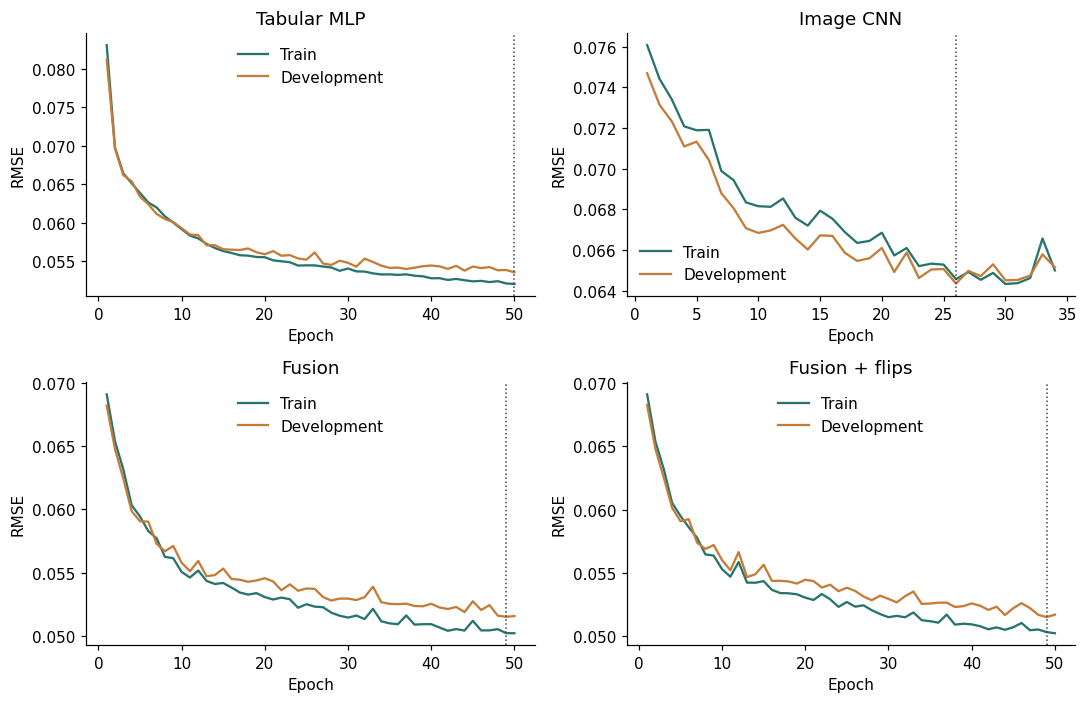

In [5]:
dev_runs, dev_rows = {}, []
for name, config in CONFIGS.items():
    result = fit_network(**config, seed=SEED,
                         fit_image=img_fit, fit_tabular=tab_fit, fit_target=y_fit,
                         dev_image=img_dev, dev_tabular=tab_dev, dev_target=y_dev)
    prediction = predict_network(result['model'], img_dev, tab_dev)
    result['prediction'] = prediction
    dev_runs[name] = result
    dev_rows.append({'model': name, **metrics(y_dev.numpy(), prediction),
                     'best_epoch': result['best_epoch'], 'epochs_run': result['epochs_run'],
                     'parameters': result['parameters'], 'training_s': result['seconds']})
    print(name, 'complete:', dev_rows[-1], flush=True)
dev_results = pd.DataFrame(dev_rows).sort_values('RMSE').reset_index(drop=True)
display(dev_results.round(6))
dev_results.to_csv(RESULTS / 'development_results.csv', index=False)
for name, result in dev_runs.items():
    result['history'].to_csv(RESULTS / (name.replace(' ', '_') + '_learning.csv'), index=False)

fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))
for ax, (name, run) in zip(axes.flat, dev_runs.items()):
    h = run['history']
    ax.plot(h.epoch, h.train_RMSE, label='Train', color='#26746c')
    ax.plot(h.epoch, h.dev_RMSE, label='Development', color='#c47c38')
    ax.axvline(run['best_epoch'], color='#444444', ls=':', lw=1)
    ax.set(title=name, xlabel='Epoch', ylabel='RMSE')
    ax.legend(frameon=False)
save_plot('learning_curves')

**Development findings.** Fusion + flips is selected at RMSE 0.051479. The image-only CNN (0.064356) is worse than the tabular MLP (0.053572); an image by itself does not capture all information needed for a next-step forecast. Unaugmented fusion reaches 0.051508, supporting a modest complementary role for appearance and context. Flipping slightly improves the recorded fusion score (change in RMSE: -0.000030). This small one-split difference should not be overinterpreted. The CNN's best checkpoint is at epoch 26; continuing beyond it does not yield a better assessment score. Models reaching their best score at epoch 50 may still benefit from a future training-budget investigation, but no budget is extended using benchmark results.

## 4. Classical controls and a check that image pairing matters
The Part A decision tree is reproduced with exactly its final inputs and settings (maximum depth 12, minimum leaf 40, seed 42). I also use a training-mean baseline. Neither is re-tuned in Part B.

A deliberately simple **tabular + RGB Ridge** model uses the 12 tabular inputs plus nine image summaries: the mean, standard deviation and 95th percentile of each RGB channel. Ridge alpha is fixed at 1; these features are scaled using only fit rows. This control checks whether a small model can exploit the synthetic colour signal; it does not establish which visual patterns the CNN uses.

The best image-using development network is also evaluated with images reassigned from a different assessment episode at the **same day**. Every reassigned image still belongs to the development partition. An error increase indicates reliance on the correct image pairing, rather than just the number of parameters. Reassignment creates inconsistent sensor-image pairs, so the result is a diagnostic rather than a realistic deployment score. It is not used for hyperparameter selection.

In [6]:
def make_tree():
    return Pipeline([('prepare', make_preprocessor(scale=False)),
                     ('model', DecisionTreeRegressor(max_depth=12, min_samples_leaf=40, random_state=SEED))])

def colour_features(array):
    scaled = array.astype(np.float32) / 255.0
    return np.concatenate([scaled.mean((1, 2)), scaled.std((1, 2)),
                           np.quantile(scaled, 0.95, axis=(1, 2))], axis=1).astype('float32')

tree_dev = make_tree().fit(data.iloc[fit_idx][FEATURES], y[fit_idx])
tree_dev_prediction = tree_dev.predict(data.iloc[dev_idx][FEATURES])
rgb_scaler_dev = StandardScaler()
rgb_fit = rgb_scaler_dev.fit_transform(colour_features(images[fit_idx]))
rgb_dev = rgb_scaler_dev.transform(colour_features(images[dev_idx]))
rgb_ridge_dev = Ridge(alpha=1.0).fit(np.column_stack([tab_fit.numpy(), rgb_fit]), y[fit_idx])
rgb_dev_prediction = rgb_ridge_dev.predict(np.column_stack([tab_dev.numpy(), rgb_dev]))
control_results = pd.DataFrame([
    {'model': 'Mean baseline', **metrics(y[dev_idx], np.repeat(y[fit_idx].mean(), len(dev_idx)))},
    {'model': 'Part A tree', **metrics(y[dev_idx], tree_dev_prediction)},
    {'model': 'Tabular + RGB Ridge', **metrics(y[dev_idx], rgb_dev_prediction)}
])
display(control_results.round(6))
control_results.to_csv(RESULTS / 'development_controls.csv', index=False)

selected_name = dev_results.iloc[0]['model']
image_rows = dev_results[dev_results.model.map(lambda n: CONFIGS[n]['mode'] != 'tabular')]
image_selected_name = image_rows.iloc[0]['model']
image_selected = dev_runs[image_selected_name]['model']
dev_frame = data.iloc[dev_idx].reset_index(drop=True)
dev_episodes = np.sort(dev_frame.episode_id.unique())
swap_episode = dict(zip(dev_episodes, np.roll(dev_episodes, 1)))
lookup = {(int(r.episode_id), int(r.day)): i for i, r in dev_frame.iterrows()}
wrong_index = np.array([lookup[(swap_episode[int(r.episode_id)], int(r.day))]
                        for _, r in dev_frame.iterrows()])
assert np.all(dev_frame.episode_id.to_numpy() != dev_frame.iloc[wrong_index].episode_id.to_numpy())
assert np.array_equal(dev_frame.day, dev_frame.iloc[wrong_index].day)
wrong_prediction = predict_network(image_selected, img_dev[wrong_index], tab_dev)
pairing_results = pd.DataFrame([
    {'condition': 'Correct current image', **metrics(y[dev_idx], dev_runs[image_selected_name]['prediction'])},
    {'condition': 'Other episode, same day', **metrics(y[dev_idx], wrong_prediction)}
])
print('Best network by development RMSE:', selected_name)
print('Image-pairing diagnostic model:', image_selected_name)
display(pairing_results.round(6))
pairing_results.to_csv(RESULTS / 'image_pairing_check.csv', index=False)

,model,RMSE,MAE,R2
0,Mean baseline,0.093948,0.077078,-0.004634
1,Part A tree,0.056035,0.041552,0.642604
2,Tabular + RGB Ridge,0.064821,0.051203,0.521740


Best network by development RMSE: Fusion + flips
Image-pairing diagnostic model: Fusion + flips


,condition,RMSE,MAE,R2
0,Correct current image,0.051479,0.037891,0.698362
1,"Other episode, same day",0.070316,0.054986,0.437213


**Control findings.** The tree's development RMSE is 0.056035; the fixed colour-summary Ridge reaches 0.064821. Correct image pairing gives RMSE 0.051479, compared with 0.070316 after another episode's same-day image is substituted. This diagnostic changes error by +0.018838. It tests the fitted network's reliance on paired images, not causal explanations or robustness to genuine camera failures. The tabular MLP remains the trained no-image ablation.

## 5. Seed sensitivity, then freeze the final procedure
I repeat the selected neural configuration with seeds 43 and 44 on the same development split. Seed 42 is retained for final fitting regardless of these scores: the best seed is **not** selected. These runs describe optimisation sensitivity, not uncertainty across new episode splits.

Before loading the supplied benchmark, I freeze the selected architecture and final epoch counts. The selected model uses the median of its three best development epochs; the other neural modality controls use their seed-42 best epochs. Each retained network is then trained from scratch on all 180 training episodes, with preprocessing refitted only on those episodes. No early stopping is performed against the supplied benchmark. This fixed-epoch refit uses more data and can behave differently from the development fit.

In [7]:
seed_rows = []
selected_seed_runs = {SEED: dev_runs[selected_name]}
for seed in [43, 44]:
    selected_seed_runs[seed] = fit_network(**CONFIGS[selected_name], seed=seed,
        fit_image=img_fit, fit_tabular=tab_fit, fit_target=y_fit,
        dev_image=img_dev, dev_tabular=tab_dev, dev_target=y_dev)
for seed, run in selected_seed_runs.items():
    p = predict_network(run['model'], img_dev, tab_dev)
    seed_rows.append({'seed': seed, 'best_epoch': run['best_epoch'],
                      'epochs_run': run['epochs_run'], 'training_s': run['seconds'],
                      **metrics(y[dev_idx], p)})
seed_results = pd.DataFrame(seed_rows)
display(seed_results.round(6))
print('Seed mean/SD development RMSE:', seed_results.RMSE.mean(), seed_results.RMSE.std(ddof=1))
seed_results.to_csv(RESULTS / 'seed_sensitivity.csv', index=False)

retained_names = ['Tabular MLP', 'Image CNN', image_selected_name]
if selected_name not in retained_names:
    retained_names.append(selected_name)
retained_names = list(dict.fromkeys(retained_names))
refit_epochs = {name: dev_runs[name]['best_epoch'] for name in retained_names}
refit_epochs[selected_name] = int(np.median(seed_results.best_epoch))
FROZEN_PLAN = {'selection_metric': 'development RMSE', 'selected_network': selected_name,
               'selected_image_network': image_selected_name, 'final_seed': SEED,
               'refit_epochs': refit_epochs, 'features': FEATURES, 'configs': CONFIGS,
               'low_health_threshold': 0.6, 'bootstrap_unit': 'episode',
               'bootstrap_replicates': 2000, 'bootstrap_seed': 2026}
(RESULTS / 'frozen_plan.json').write_text(json.dumps(FROZEN_PLAN, indent=2))
print('FROZEN BEFORE BENCHMARK EVALUATION:')
print(json.dumps(FROZEN_PLAN, indent=2))

pre_final = make_preprocessor()
tab_all_np = pre_final.fit_transform(data[FEATURES]).astype('float32')
tab_all = torch.from_numpy(tab_all_np)
mean_final, std_final = image_stats(images)
img_all = image_tensor(images, mean_final, std_final)
y_all = torch.from_numpy(y)
final_runs = {}
for name in retained_names:
    final_runs[name] = fit_network(**CONFIGS[name], seed=SEED,
        fit_image=img_all, fit_tabular=tab_all, fit_target=y_all,
        fixed_epochs=refit_epochs[name])
    print('Final refit complete:', name, 'epochs:', refit_epochs[name],
          'seconds:', round(final_runs[name]['seconds'], 2), flush=True)

tree_start = time.perf_counter()
tree_final = make_tree().fit(data[FEATURES], y)
tree_fit_seconds = time.perf_counter() - tree_start
rgb_scaler_final = StandardScaler()
rgb_all = rgb_scaler_final.fit_transform(colour_features(images))
ridge_start = time.perf_counter()
rgb_ridge_final = Ridge(alpha=1.0).fit(np.column_stack([tab_all_np, rgb_all]), y)
rgb_fit_seconds = time.perf_counter() - ridge_start
print('All final fits complete. No supplied benchmark labels were used for these decisions.')

fusion, seed 43, flips=True: epoch 1, train RMSE 0.07048, dev RMSE 0.06946
fusion, seed 43, flips=True: epoch 10, train RMSE 0.05549, dev RMSE 0.05600
fusion, seed 43, flips=True: epoch 20, train RMSE 0.05354, dev RMSE 0.05404
fusion, seed 43, flips=True: epoch 30, train RMSE 0.05230, dev RMSE 0.05372
fusion, seed 43, flips=True: epoch 40, train RMSE 0.05081, dev RMSE 0.05186
fusion, seed 43, flips=True: epoch 50, train RMSE 0.05009, dev RMSE 0.05168
fusion, seed 44, flips=True: epoch 1, train RMSE 0.07367, dev RMSE 0.07288
fusion, seed 44, flips=True: epoch 10, train RMSE 0.05877, dev RMSE 0.05871
fusion, seed 44, flips=True: epoch 20, train RMSE 0.05410, dev RMSE 0.05555
fusion, seed 44, flips=True: epoch 30, train RMSE 0.05268, dev RMSE 0.05359
fusion, seed 44, flips=True: epoch 40, train RMSE 0.05107, dev RMSE 0.05245
fusion, seed 44, flips=True: epoch 50, train RMSE 0.05046, dev RMSE 0.05170


,seed,best_epoch,epochs_run,training_s,RMSE,MAE,R2
0,42,49,50,105.512765,0.051479,0.037891,0.698362
1,43,47,50,97.286451,0.051320,0.038208,0.700214
2,44,49,50,99.943799,0.051578,0.038074,0.697200


Seed mean/SD development RMSE: 0.05145891669887418 0.00012979538320256477
FROZEN BEFORE BENCHMARK EVALUATION:
{
  "selection_metric": "development RMSE",
  "selected_network": "Fusion + flips",
  "selected_image_network": "Fusion + flips",
  "final_seed": 42,
  "refit_epochs": {
    "Tabular MLP": 50,
    "Image CNN": 26,
    "Fusion + flips": 49
  },
  "features": [
    "day",
    "outside_temp_c",
    "outside_humidity_pct",
    "solar_w_m2",
    "inside_temp_c",
    "inside_humidity_pct",
    "co2_ppm",
    "soil_moisture",
    "vpd_kpa",
    "cultivar",
    "season",
    "action_name"
  ],
  "configs": {
    "Tabular MLP": {
      "mode": "tabular",
      "flips": false
    },
    "Image CNN": {
      "mode": "image",
      "flips": false
    },
    "Fusion": {
      "mode": "fusion",
      "flips": false
    },
    "Fusion + flips": {
      "mode": "fusion",
      "flips": true
    }
  },
  "low_health_threshold": 0.6,
  "bootstrap_unit": "episode",
  "bootstrap_replicates": 2000,

**Frozen refit decision.** Selected-network development RMSE across seeds 42/43/44 has mean 0.051459 and sample SD 0.000130. Best epochs are 49, 47, 49; their median is used for the selected refit. The final seed stays 42. Fixed final epochs are **Tabular MLP: 50; Image CNN: 26; Fusion + flips: 49**. These decisions precede the benchmark-loading cell below. Refitting all training episodes increases both the available data and the number of updates per epoch, so its result need not exactly match the development score.

## 6. Common final benchmark: the same episodes as Part A
The supplied validation files are now opened for evaluation. All fitted models predict the same 1,770 labelled rows from 30 episodes not used for training. Reproducing the submitted tree result checks continuity with Part A. The previous Part A holdout score was already known, so this is a reused project benchmark; it is weaker evidence than a newly collected blind test set.

Metrics use health-score units. A reduction in RMSE is not a classification accuracy, and the 1,770 adjacent observations are not independent trials. Predictions from neural networks are bounded by their sigmoid output. Ridge is deliberately left unclipped so its behaviour is visible.

,split,raw_rows,episodes,labelled_rows,images,missing_inputs
0,Training,10800,180,10620,10800,0
1,Final benchmark,1800,30,1770,1800,0


,model,RMSE,MAE,R2,outside_0_1
0,Mean baseline,0.093908,0.076988,-0.000261,0
1,Part A tree,0.055255,0.041652,0.653701,0
2,Tabular + RGB Ridge,0.064739,0.051393,0.524621,0
3,Tabular MLP,0.053579,0.040982,0.674386,0
4,Image CNN,0.065599,0.050010,0.511901,0
5,Fusion + flips,0.050909,0.038523,0.706032,0


Submitted Part A RMSE reproduced within rounding: 0.05525473658240315
Selected-network RMSE reduction vs Part A (%): 7.865056261561765


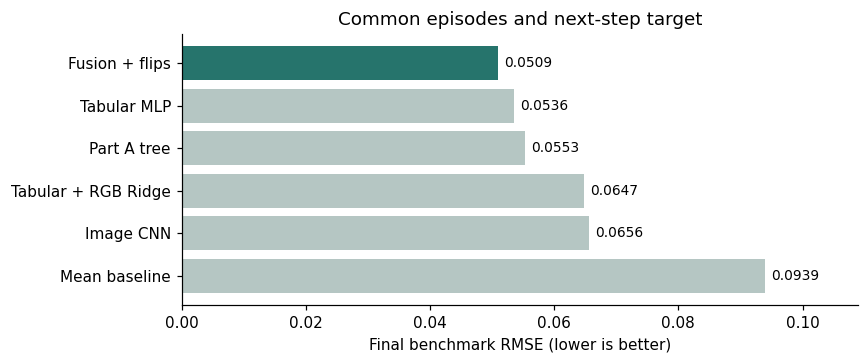

In [8]:
benchmark_raw = read_csv('validation.csv')
benchmark_images_raw = read_images('validation_images.npz')
benchmark_audit = audit_split(benchmark_raw, benchmark_images_raw, 'Final benchmark')
assert set(train_raw.episode_id).isdisjoint(set(benchmark_raw.episode_id))
benchmark = benchmark_raw.dropna(subset=[TARGET]).reset_index(drop=True)
benchmark_images = benchmark_images_raw[benchmark.image_index.to_numpy()]
actual = benchmark[TARGET].to_numpy()
benchmark_hashes = {hashlib.sha256(a.tobytes()).hexdigest() for a in benchmark_images}
assert not set(image_hashes) & benchmark_hashes
tab_test_np = pre_final.transform(benchmark[FEATURES]).astype('float32')
tab_test = torch.from_numpy(tab_test_np)
img_test = image_tensor(benchmark_images, mean_final, std_final)
rgb_test = rgb_scaler_final.transform(colour_features(benchmark_images))
predictions = {'Mean baseline': np.repeat(float(y.mean()), len(benchmark)),
               'Part A tree': tree_final.predict(benchmark[FEATURES]),
               'Tabular + RGB Ridge': rgb_ridge_final.predict(np.column_stack([tab_test_np, rgb_test]))}
for name, run in final_runs.items():
    predictions[name] = predict_network(run['model'], img_test, tab_test)

benchmark_results = pd.DataFrame([{'model': name, **metrics(actual, p),
    'outside_0_1': int(np.sum((p < 0) | (p > 1)))} for name, p in predictions.items()])
display(pd.DataFrame([train_audit, benchmark_audit]))
display(benchmark_results.round(6))
tree_rmse = metrics(actual, predictions['Part A tree'])['RMSE']
assert abs(tree_rmse - 0.055255) < 0.000001
print('Submitted Part A RMSE reproduced within rounding:', tree_rmse)
print('Selected-network RMSE reduction vs Part A (%):',
      100 * (1 - metrics(actual, predictions[selected_name])['RMSE'] / tree_rmse))
benchmark_results.to_csv(RESULTS / 'benchmark_results.csv', index=False)
prediction_table = benchmark[['episode_id', 'day', 'season', 'cultivar', 'action_name']].copy()
prediction_table['actual'] = actual
for name, p in predictions.items():
    prediction_table[name] = p
prediction_table.to_csv(RESULTS / 'benchmark_predictions.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 3.4))
ordered = benchmark_results.sort_values('RMSE', ascending=False)
ax.barh(ordered.model, ordered.RMSE, color=['#b5c6c3' if n != selected_name else '#26746c' for n in ordered.model])
ax.set(xlabel='Final benchmark RMSE (lower is better)', title='Common episodes and next-step target')
for i, value in enumerate(ordered.RMSE):
    ax.text(value + 0.001, i, f'{value:.4f}', va='center', fontsize=9)
ax.set_xlim(0, ordered.RMSE.max() * 1.16)
save_plot('benchmark_comparison')

**Final benchmark findings.** The development-selected Fusion + flips obtains RMSE **0.050909**, MAE **0.038523** and R-squared **0.7060**. The reproduced Part A tree RMSE is **0.055255**: the reduction is **7.9%**. The tabular MLP reaches 0.053579, image-only CNN 0.065599, and colour-summary Ridge 0.064739. This separates extra visual information from merely replacing the tabular learner. The reused benchmark is not used to change the selected architecture, even if its ranking differs from development.

## 7. Error analysis and uncertainty at the episode level
I retain Part A's diagnostic low-health cutoff of **actual next health < 0.6**. This is an example for inspecting failure, not a validated agronomic alert threshold. Positive mean error means overprediction. I compare the selected network with the tree within the same low-health rows and report season/cultivar groups with their episode counts.

For paired RMSE differences, I resample entire episodes with replacement (2,000 bootstrap samples, seed 2026), applying the same resample to both models. A negative difference favours the selected network. The percentile interval describes variation under resampling these 30 synthetic episodes, conditional on the fitted models. It excludes uncertainty from retraining, model selection and reuse of the Part A benchmark; it is not a guarantee of field performance. All episodes have 59 labelled rows, so row weighting and equal episode weighting coincide for squared error.

,model,rows,episodes,RMSE,MAE,R2,mean_error
0,Part A tree,105,20,0.093281,0.070891,-9.413932,0.067750
1,Tabular MLP,105,20,0.093529,0.080083,-9.469262,0.079892
2,Image CNN,105,20,0.098615,0.089457,-10.639032,0.089363
3,Fusion + flips,105,20,0.080113,0.063825,-6.681301,0.063034


,group,value,rows,episodes,tree_RMSE,selected_RMSE,selected_mean_error
0,season,cool,531,9,0.058079,0.051360,-0.005309
1,season,mild,767,13,0.055821,0.050912,-0.006021
2,season,warm,472,8,0.050899,0.050392,-0.006081
3,cultivar,A,177,3,0.053024,0.048404,-0.002190
4,cultivar,B,885,15,0.057692,0.053033,-0.007368
5,cultivar,C,708,12,0.052625,0.048765,-0.004802


,comparison,RMSE_difference,CI_2.5%,CI_97.5%
0,Fusion + flips minus Part A tree,-0.004346,-0.006299,-0.002378
1,Fusion + flips minus Tabular MLP,-0.002670,-0.003632,-0.001719
2,Fusion + flips minus Image CNN,-0.014690,-0.017010,-0.012289
3,Fusion + flips minus Tabular + RGB Ridge,-0.013830,-0.015641,-0.011721


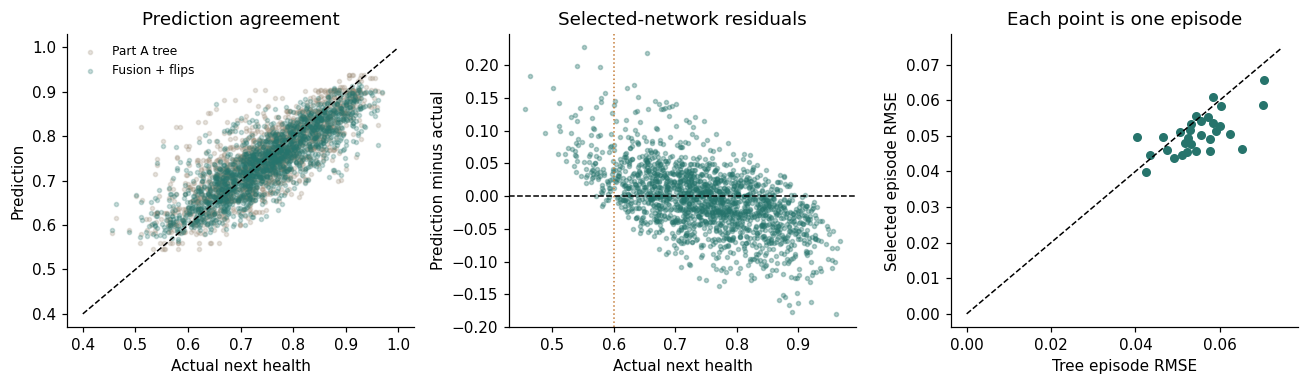

Episodes where selected network has lower RMSE than tree: 23 / 30


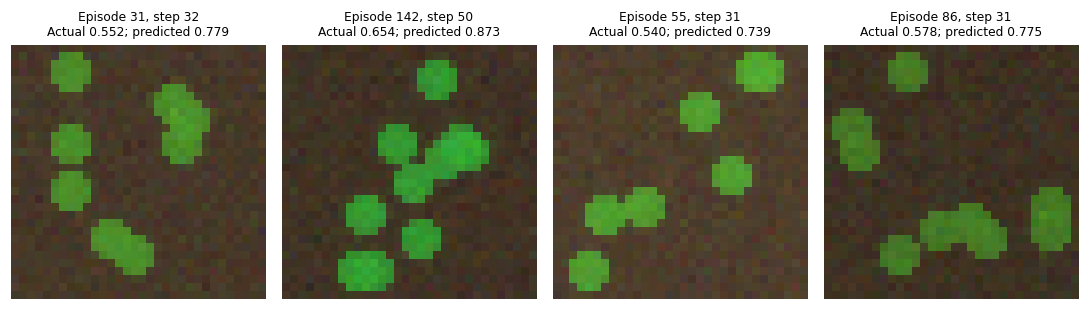

In [9]:
selected_prediction = predictions[selected_name]
low = actual < FROZEN_PLAN['low_health_threshold']
low_results = pd.DataFrame([{'model': name, 'rows': int(low.sum()),
    'episodes': int(benchmark.loc[low, 'episode_id'].nunique()),
    **metrics(actual[low], predictions[name][low]),
    'mean_error': float(np.mean(predictions[name][low] - actual[low]))}
    for name in ['Part A tree', 'Tabular MLP', 'Image CNN', selected_name]])
low_results = low_results.drop_duplicates('model')
display(low_results.round(6))
low_results.to_csv(RESULTS / 'low_health_results.csv', index=False)

group_rows = []
for field in ['season', 'cultivar']:
    for label, rows in benchmark.groupby(field):
        ix = rows.index.to_numpy()
        group_rows.append({'group': field, 'value': label, 'rows': len(ix),
            'episodes': rows.episode_id.nunique(),
            'tree_RMSE': metrics(actual[ix], predictions['Part A tree'][ix])['RMSE'],
            'selected_RMSE': metrics(actual[ix], selected_prediction[ix])['RMSE'],
            'selected_mean_error': float(np.mean(selected_prediction[ix] - actual[ix]))})
subgroup_results = pd.DataFrame(group_rows)
display(subgroup_results.round(6))
subgroup_results.to_csv(RESULTS / 'subgroup_results.csv', index=False)

episode_ids = np.sort(benchmark.episode_id.unique())
episode_indices = [np.flatnonzero(benchmark.episode_id.to_numpy() == e) for e in episode_ids]
assert all(len(ix) == 59 for ix in episode_indices)
rng = np.random.default_rng(FROZEN_PLAN['bootstrap_seed'])
resampled = rng.integers(0, len(episode_ids), size=(FROZEN_PLAN['bootstrap_replicates'], len(episode_ids)))
selected_episode_mse = np.array([np.mean((actual[ix] - selected_prediction[ix]) ** 2) for ix in episode_indices])
bootstrap_rows = []
for reference in ['Part A tree', 'Tabular MLP', 'Image CNN', 'Tabular + RGB Ridge']:
    if reference == selected_name:
        continue
    reference_mse = np.array([np.mean((actual[ix] - predictions[reference][ix]) ** 2) for ix in episode_indices])
    differences = np.sqrt(selected_episode_mse[resampled].mean(axis=1)) - np.sqrt(reference_mse[resampled].mean(axis=1))
    lo, hi = np.quantile(differences, [0.025, 0.975])
    bootstrap_rows.append({'comparison': f'{selected_name} minus {reference}',
        'RMSE_difference': metrics(actual, selected_prediction)['RMSE'] - metrics(actual, predictions[reference])['RMSE'],
        'CI_2.5%': float(lo), 'CI_97.5%': float(hi)})
bootstrap_results = pd.DataFrame(bootstrap_rows)
display(bootstrap_results.round(6))
bootstrap_results.to_csv(RESULTS / 'paired_episode_bootstrap.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for name, colour in [('Part A tree', '#9f8f7b'), (selected_name, '#26746c')]:
    axes[0].scatter(actual, predictions[name], s=7, alpha=0.25, label=name, color=colour)
axes[0].plot([0.4, 1.0], [0.4, 1.0], 'k--', lw=1)
axes[0].set(xlabel='Actual next health', ylabel='Prediction', title='Prediction agreement')
axes[0].legend(frameon=False, fontsize=8)
axes[1].scatter(actual, selected_prediction - actual, s=7, alpha=0.35, color='#26746c')
axes[1].axhline(0, color='black', ls='--', lw=1)
axes[1].axvline(0.6, color='#c47c38', ls=':', lw=1)
axes[1].set(xlabel='Actual next health', ylabel='Prediction minus actual', title='Selected-network residuals')
ep_rmse = pd.DataFrame([{'tree': metrics(actual[ix], predictions['Part A tree'][ix])['RMSE'],
                         'selected': metrics(actual[ix], selected_prediction[ix])['RMSE']}
                        for ix in episode_indices])
axes[2].scatter(ep_rmse.tree, ep_rmse.selected, color='#26746c', s=24)
limit = max(ep_rmse.max()) * 1.06
axes[2].plot([0, limit], [0, limit], 'k--', lw=1)
axes[2].set(xlabel='Tree episode RMSE', ylabel='Selected episode RMSE', title='Each point is one episode')
save_plot('error_diagnostics')
print('Episodes where selected network has lower RMSE than tree:', int((ep_rmse.selected < ep_rmse.tree).sum()), '/', len(ep_rmse))

worst_rows = np.argsort(np.abs(selected_prediction - actual))[-4:][::-1]
fig, axes = plt.subplots(1, 4, figsize=(10, 2.8))
for ax, i in zip(axes, worst_rows):
    ax.imshow(benchmark_images[i])
    row = benchmark.iloc[i]
    ax.set_title(f'Episode {row.episode_id}, step {row.day}\nActual {actual[i]:.3f}; predicted {selected_prediction[i]:.3f}', fontsize=8)
    ax.axis('off')
save_plot('largest_errors')

**Reliability findings.** Below actual health 0.6, selected-network RMSE is **0.080113**, compared with the tree's **0.093281**. Its mean error is **0.063034**; positive values indicate potentially misleading optimism about crop health. Narrow-range subgroup R-squared can be unstable, so RMSE, MAE and signed error are the more useful diagnostics here. The selected model beats the tree within 23 of 30 episodes. The paired episode-bootstrap RMSE difference versus the tabular MLP is -0.002670, with interval [-0.003632, -0.001719]. The interval is below zero, supporting lower error than the tabular MLP on these synthetic episodes. These intervals resample the available episodes; they do not account for real-world domain shift or the benchmark's prior use in Part A. An average improvement does not validate a stress alarm.

## 8. Computational cost and practical trade-offs
Parameter counts describe network capacity; raw float32 weight size is `4 * parameters` bytes, excluding preprocessing and framework overhead. Wall times are measured on this CPU with four threads, so they are not portable hardware benchmarks. Inference times below are medians of five warmed **whole-benchmark batches**, divided by row count, and exclude data loading/preprocessing. They are throughput figures, not single-camera latency.

The sensor pipeline, image capture and normalisation also have costs. The colour baseline requires image summary extraction. Its reported fit time below excludes that extraction, just as neural fit timing excludes initial normalisation. No model is assumed more practical solely because its test RMSE is lower.

In [10]:
def median_prediction_ms(function, repeats=5):
    function()  # Warm up.
    elapsed = []
    for _ in range(repeats):
        start = time.perf_counter()
        function()
        elapsed.append(time.perf_counter() - start)
    return 1000 * float(np.median(elapsed)) / len(benchmark)

cost_rows = [
    {'model': 'Part A tree', 'parameters': np.nan, 'weight_KiB': np.nan,
     'fit_s': tree_fit_seconds, 'ms_per_row': median_prediction_ms(lambda: tree_final.predict(benchmark[FEATURES])),
     'detail': f'{tree_final.named_steps["model"].tree_.node_count} tree nodes'},
    {'model': 'Tabular + RGB Ridge', 'parameters': rgb_ridge_final.coef_.size + 1,
     'weight_KiB': (rgb_ridge_final.coef_.nbytes + np.asarray(rgb_ridge_final.intercept_).nbytes) / 1024,
     'fit_s': rgb_fit_seconds,
     'ms_per_row': median_prediction_ms(lambda: rgb_ridge_final.predict(np.column_stack([tab_test_np, rgb_test]))),
     'detail': 'Image feature extraction excluded'}]
for name, run in final_runs.items():
    cost_rows.append({'model': name, 'parameters': run['parameters'],
        'weight_KiB': 4 * run['parameters'] / 1024, 'fit_s': run['seconds'],
        'ms_per_row': median_prediction_ms(lambda r=run: predict_network(r['model'], img_test, tab_test)),
        'detail': f'{refit_epochs[name]} fixed epochs; CPU'})
cost_results = pd.DataFrame(cost_rows)
display(cost_results.round(5))
cost_results.to_csv(RESULTS / 'computational_cost.csv', index=False)
development_total_s = sum(r['seconds'] for r in dev_runs.values()) + sum(r['seconds'] for s, r in selected_seed_runs.items() if s != SEED)
final_neural_total_s = sum(r['seconds'] for r in final_runs.values())
print(f'Measured neural training/evaluation-loop time: development {development_total_s/60:.2f} min; final refits {final_neural_total_s/60:.2f} min.')
print('Includes per-epoch train/development predictions; excludes setup, data loading, plotting and report creation.')

,model,parameters,weight_KiB,fit_s,ms_per_row,detail
0,Part A tree,NaN,NaN,0.08222,0.00201,405 tree nodes
1,Tabular + RGB Ridge,31.0,0.12109,0.00248,0.00004,Image feature extraction excluded
2,Tabular MLP,1809.0,7.06641,6.30285,0.00078,50 fixed epochs; CPU
3,Image CNN,7121.0,27.81641,62.84304,0.07124,26 fixed epochs; CPU
4,Fusion + flips,8865.0,34.62891,115.85492,0.06357,49 fixed epochs; CPU


Measured neural training/evaluation-loop time: development 7.95 min; final refits 3.08 min.
Includes per-epoch train/development predictions; excludes setup, data loading, plotting and report creation.


**Cost findings.** The combined development training/evaluation loops take 7.95 minutes, and final neural refits take 3.08 minutes on this CPU. The modest models therefore fit the assignment's no-paid-GPU constraint. Their measured batch throughput excludes image capture/preprocessing and should not be presented as single-image latency. Real deployment would also require trustworthy sensor readings, camera timing and health labels.

## 9. Interpretation, limitations and final checks
The printed summary below is computed from the saved predictions. Model selection remains the development decision even if another model happens to score better on the final benchmark. The report discusses the modality comparison, simpler colour control, low-health errors and computational cost together.

**Limits:** these are synthetic, low-resolution images, not evidence of recognising real plant disease. The renderer may encode health through colour, giving an easier task than field images. The crop images add a current visual observation that Part A did not have, so an improvement cannot be attributed to neural architecture alone. The image timestamp convention is assumed from the supplied join. Development uses one episode split; three seeds measure optimisation sensitivity only. Part A already exposed the final benchmark, and repeated project use limits its independence. The same simulator and operating policy generate all splits. There is no external greenhouse test, camera shift test, calibrated prediction interval or validated alarm threshold. The model predicts under logged actions, without estimating causal intervention effects. Poor-health cases are relatively uncommon, and future collection should deliberately cover them.

**Next steps:** collect independently labelled real crop images and sensor episodes, verify capture timing, and perform a new blind episode-level test with different lighting/cameras and more stressed crops. Consider temporal history only with a revised fair baseline. Reliability under sensor/camera failures needs separate experiments.

In [11]:
selected_metrics = metrics(actual, selected_prediction)
tree_metrics = metrics(actual, predictions['Part A tree'])
summary = {
    'selected_network': selected_name, 'image_network': image_selected_name,
    'selected_metrics': selected_metrics, 'tree_metrics': tree_metrics,
    'rmse_reduction_vs_tree_pct': 100 * (1 - selected_metrics['RMSE'] / tree_metrics['RMSE']),
    'development_seed_RMSE_mean': float(seed_results.RMSE.mean()),
    'development_seed_RMSE_sd': float(seed_results.RMSE.std(ddof=1)),
    'development_total_s': development_total_s, 'final_neural_total_s': final_neural_total_s,
    'better_episodes_vs_tree': int((ep_rmse.selected < ep_rmse.tree).sum()),
    'versions': versions, 'refit_epochs': refit_epochs,
    'training_audit': {k: int(v) if isinstance(v, np.integer) else v for k,v in train_audit.items()},
    'benchmark_audit': {k: int(v) if isinstance(v, np.integer) else v for k,v in benchmark_audit.items()}
}
(RESULTS / 'summary.json').write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))
assert len(data) == 10620 and len(benchmark) == 1770
assert len(np.unique(groups)) == 180 and benchmark.episode_id.nunique() == 30
assert len(FEATURES) == 12 and tab_all.shape[1] == 21
assert len(dev_results) == 4 and len(seed_results) == 3
assert FROZEN_PLAN['final_seed'] == 42
assert set(FEATURES).isdisjoint(FORBIDDEN)
assert all(len(p) == len(actual) and np.isfinite(p).all() for p in predictions.values())
assert all(((predictions[n] >= 0) & (predictions[n] <= 1)).all() for n in final_runs)
assert set(groups).isdisjoint(benchmark.episode_id)
assert not set(image_hashes) & benchmark_hashes
print('All final data, leakage, pairing, Part A reproduction and prediction checks passed.')

{
  "selected_network": "Fusion + flips",
  "image_network": "Fusion + flips",
  "selected_metrics": {
    "RMSE": 0.0509089204630194,
    "MAE": 0.038522780807868404,
    "R2": 0.70603214157946
  },
  "tree_metrics": {
    "RMSE": 0.05525473658240315,
    "MAE": 0.041652046484035435,
    "R2": 0.6537011107409553
  },
  "rmse_reduction_vs_tree_pct": 7.865056261561765,
  "development_seed_RMSE_mean": 0.05145891669887418,
  "development_seed_RMSE_sd": 0.00012979538320256477,
  "development_total_s": 477.18930086299997,
  "final_neural_total_s": 185.00081453999996,
  "better_episodes_vs_tree": 23,
  "versions": {
    "Python": "3.12.14",
    "PyTorch": "2.14.1+cpu",
    "NumPy": "2.3.5",
    "pandas": "2.2.3",
    "scikit-learn": "1.8.0",
    "Matplotlib": "3.10.8"
  },
  "refit_epochs": {
    "Tabular MLP": 50,
    "Image CNN": 26,
    "Fusion + flips": 49
  },
  "training_audit": {
    "split": "Training",
    "raw_rows": 10800,
    "episodes": 180,
    "labelled_rows": 10620,
    "imag

## References
1. Supplied COMP3032 Two-Part Applied Project brief and `data_dictionary.csv`; submitted Part A report and notebook (Mohammad Adib (Eddie) Amiri).
2. PyTorch, [Conv2d](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Conv2d.html), [MSELoss](https://docs.pytorch.org/docs/2.14/generated/torch.nn.MSELoss.html) and [Adam](https://docs.pytorch.org/docs/2.14/generated/torch.optim.Adam.html). Convolution, regression loss and optimiser implementations.
3. PyTorch, [Reproducibility](https://docs.pytorch.org/docs/2.14/notes/randomness.html). Seeds and deterministic algorithms do not promise bitwise agreement across releases or hardware.
4. scikit-learn, [GroupKFold](https://scikit-learn.org/1.8/modules/generated/sklearn.model_selection.GroupKFold.html) and [common pitfalls](https://scikit-learn.org/1.8/common_pitfalls.html). Episode separation and fitting preprocessing only on training data.

All modelling and analysis code is included above. No unseen pretrained model, separate script or manually entered experimental score is needed to reproduce the investigation.